# Lucrare de laborator: Agent AI cu unelte, bază de date și RAG

**Student:** Daniel Pănuța, grupa IASD 2501 · **Disciplina:** Inteligența artificială generativă · **Profesor:** V. Ursachi

**Sarcina** (anunțată la oră, fără document scris): un **agent** cu 2–3 unelte (*tools*) și o **bază de date**, care rezolvă singur o sarcină mică.

**Ce am construit.** Un *asistent pentru secretariatul de master*. Răspunde la întrebări despre studenți, note și credite, verificând regulile din **Regulamentul USM pentru studiile de master**, același document ca la laboratorul RAG. Agentul are 3 unelte:

| Unealtă | Ce face | Sursa |
|---|---|---|
| `interogare_sql` | rulează o interogare `SELECT` pe baza de date | SQLite `data/universitate.db` (date fictive) |
| `cauta_regulament` | caută punctele relevante din regulament | RAG-ul din laboratorul anterior: BM25 + dens + reranker |
| `calculeaza` | evaluează o expresie aritmetică | Python, evaluare sigură |

**De ce e nevoie de un agent, nu doar de RAG.** O întrebare ca „*Are Natalia Bălan media necesară pentru mobilitate academică?*” cere mai mulți pași:

1. aflu media și profilul ei din baza de date;
2. aflu pragul pentru profilul ei din regulament;
3. compar cele două valori.

Niciuna dintre surse nu are singură răspunsul. Modelul trebuie să **decidă** ce unealtă să folosească, cu ce argumente și când are destule informații ca să răspundă.

**Bucla agentului** (tiparul *ReAct*: raționament + acțiune):

```
întrebare ──► LLM ──► vrea o unealtă? ──da──► rulez unealta ──► rezultatul revine la LLM ──┐
                ▲                                                                          │
                └──────────────────────────────────────────────────────────────────────────┘
                         nu ──► răspunsul final
```

**Pașii lucrării:**

1. Baza de date.
2. Uneltele.
3. Modelul și bucla agentului.
4. Demo cu urmele pașilor (*trace*).
5. Evaluarea pe 13 sarcini.
6. Comparația cu modelul fără unelte.
7. Experimentele: schema bazei în prompt sau nu; modelul 7B față de 3B.
8. Concluzii.

## 0. Mediul de lucru

Notebook-ul e rulat pe **Google Colab, GPU T4**. Agentul principal folosește `Qwen/Qwen2.5-7B-Instruct`, încărcat **pe 4 biți** (cuantizare NF4 cu `bitsandbytes`): ~5,5 GB în loc de ~15 GB, deci încape pe T4. Pentru comparație folosesc și `Qwen/Qwen2.5-3B-Instruct` (float16, ~6 GB). Niciunul nu încape confortabil în cei 8 GB ai Mac-ului.

Qwen2.5 a fost antrenat pentru *tool calling*. Primește descrierea uneltelor în format JSON, iar când vrea să folosească una scrie `<tool_call>{"name": …, "arguments": {…}}</tool_call>`.

**Baza de date** am creat-o **local**, cu scriptul `creeaza_baza.py` din același folder, și am încărcat fișierul pe Colab. Dacă fișierul lipsește, celula de mai jos cere încărcarea lui. Regulamentul (PDF) se descarcă automat de pe usm.md.

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf", "rank_bm25", "sentence-transformers", "transformers<5", "bitsandbytes"], check=True)

In [2]:
import os, re, json, time, ast, operator, random, sqlite3, unicodedata, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pymupdf
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM
import transformers

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
LLM_NAME = os.environ.get("LABRAG_LLM", "Qwen/Qwen2.5-7B-Instruct")          # agentul principal (4 biți pe GPU)
LLM_SMALL = os.environ.get("LABRAG_LLM_SMALL", "Qwen/Qwen2.5-3B-Instruct")   # pentru experimentul 7.2
os.makedirs("data", exist_ok=True); os.makedirs("artifacts", exist_ok=True)
DB_PATH = "data/universitate.db"
PDF_PATH = "data/Regulament_master_USM.pdf"

if not os.path.exists(DB_PATH):
    if IN_COLAB:
        from google.colab import files
        print("Încărcați fișierul universitate.db (creat local cu creeaza_baza.py):")
        up = files.upload()
        with open(DB_PATH, "wb") as f:
            f.write(up[next(iter(up))])
    else:
        raise FileNotFoundError("Rulați întâi: python creeaza_baza.py")
if not os.path.exists(PDF_PATH):
    urllib.request.urlretrieve("https://usm.md/wp-content/uploads/Anexa-2.1.18.-Regulament-de-organizare-si-desfasurare-"
                               "a-studiilor-superioare-de-master-ciclul-II.pdf", PDF_PATH)
print(f"PyTorch {torch.__version__} | transformers {transformers.__version__} | dispozitiv: {device} | modele: {LLM_NAME}, {LLM_SMALL}")

Încărcați fișierul universitate.db (creat local cu creeaza_baza.py):


Saving universitate.db to universitate.db
PyTorch 2.11.0+cu130 | transformers 4.57.6 | dispozitiv: cuda | modele: Qwen/Qwen2.5-7B-Instruct, Qwen/Qwen2.5-3B-Instruct


## 1. Baza de date

Baza `universitate.db` are 4 tabele, cu **date fictive** (nume și note generate aleator, cu seed fix):

- `programe`: 4 programe de master (2 cu profil real, 2 umanist; unul de 90 de credite, celelalte de 120);
- `studenti`: 24 de studenți, cu forma de învățământ, finanțarea și media de la licență;
- `discipline`: 8 discipline pe program, 30 de credite pe semestru (pct. 39 din regulament);
- `note`: 192 de note, inclusiv 2 restanțe (nota < 5).

Am generat datele **în acord cu regulamentul**: frecvența redusă doar cu taxă (pct. 54), iar Psihologia doar cu frecvență (pct. 45). Agentul poate verifica singur aceste reguli.

In [3]:
con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)       # doar citire: agentul nu poate modifica baza
SCHEMA = "\n".join(r[0] + ";" for r in con.execute("SELECT sql FROM sqlite_master WHERE type='table'"))
print(SCHEMA, "\n")
for t in ("programe", "studenti", "discipline", "note"):
    print(f"{t:10s}: {con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0]} rânduri")
display(pd.read_sql("SELECT * FROM programe", con))
display(pd.read_sql("SELECT * FROM studenti LIMIT 6", con))

CREATE TABLE programe (
        id INTEGER PRIMARY KEY, denumire TEXT NOT NULL, domeniu TEXT NOT NULL,
        tip TEXT CHECK (tip IN ('științific', 'profesional')),
        profil TEXT CHECK (profil IN ('real', 'umanist')), credite_total INTEGER);
CREATE TABLE studenti (
        id INTEGER PRIMARY KEY, nume TEXT NOT NULL, prenume TEXT NOT NULL,
        program_id INTEGER REFERENCES programe(id), an_studii INTEGER,
        forma TEXT CHECK (forma IN ('frecvență', 'frecvență redusă')),
        finantare TEXT CHECK (finantare IN ('buget', 'taxă')), media_licenta REAL);
CREATE TABLE discipline (
        id INTEGER PRIMARY KEY, program_id INTEGER REFERENCES programe(id),
        denumire TEXT NOT NULL, semestru INTEGER, credite INTEGER);
CREATE TABLE note (
        student_id INTEGER REFERENCES studenti(id), disciplina_id INTEGER REFERENCES discipline(id),
        nota INTEGER CHECK (nota BETWEEN 1 AND 10), PRIMARY KEY (student_id, disciplina_id)); 

programe  : 4 rânduri
studenti  : 24 râ

,id,denumire,domeniu,tip,profil,credite_total
0,1,Inteligență Artificială și Știința Datelor,Informatică,profesional,real,120
1,2,Securitate Informațională,Informatică,profesional,real,120
2,3,Psihologie Clinică,Psihologie,științific,umanist,120
3,4,Drept Internațional,Drept,științific,umanist,90


,id,nume,prenume,program_id,an_studii,forma,finantare,media_licenta
0,1,Lungu,Corina,1,2,frecvență redusă,taxă,7.46
1,2,Ceban,Mihai,1,2,frecvență,buget,7.36
2,3,Rotaru,Nicolae,1,2,frecvență redusă,taxă,9.86
3,4,Bălan,Natalia,1,2,frecvență,taxă,8.84
4,5,Sârbu,Olesea,1,2,frecvență,buget,9.33
5,6,Munteanu,Valentina,1,2,frecvență,taxă,9.16


## 2. Uneltele

### 2.1 `interogare_sql`

Rulează o interogare SQL și întoarce cel mult 30 de rânduri, ca text. Pentru siguranță:

- conexiunea e deschisă **doar pentru citire** (`mode=ro`), iar în plus accept doar interogări care încep cu `SELECT` sau `WITH`;
- o eroare SQL **nu oprește** agentul: mesajul erorii îi e trimis înapoi, ca să-și corecteze interogarea;
- la un **rezultat gol** (niciun rând sau doar `None`) unealta adaugă un indiciu: verifică dacă prenumele și numele nu sunt inversate și dacă toate filtrele sunt cerute de întrebare. Am adăugat indiciul după prima rulare, în care agentul renunța imediat la un rezultat gol (vezi secțiunea 3).

In [4]:
def interogare_sql(query: str) -> str:
    q = query.strip().rstrip(";")
    if not re.match(r"(?is)^\s*(select|with)\b", q):
        return "EROARE: sunt permise doar interogări SELECT."
    try:
        cur = con.execute(q)
        rows = cur.fetchmany(31)
        cols = [d[0] for d in cur.description]
    except Exception as e:
        return f"EROARE SQL: {e}"
    GOL = ("\n(Rezultat gol. Verifică: prenume și nume nu sunt inversate? Toate filtrele sunt cerute de întrebare? "
           "Textul e scris exact ca în bază, cu diacritice? Corectează interogarea și încearcă din nou.)")
    if not rows:
        return "Niciun rând." + GOL
    if all(v is None for r in rows for v in r):
        return " | ".join(cols) + "\nNone" + GOL
    lines = [" | ".join(cols)] + [" | ".join(str(round(v, 4)) if isinstance(v, float) else str(v) for v in r) for r in rows[:30]]
    if len(rows) > 30: lines.append("... (rezultat trunchiat la 30 de rânduri)")
    return "\n".join(lines)

print(interogare_sql("SELECT forma, finantare, COUNT(*) AS n FROM studenti GROUP BY forma, finantare"))
print(interogare_sql("DELETE FROM note"))
print(interogare_sql("SELECT nume FROM studentii"))

forma | finantare | n
frecvență | buget | 7
frecvență | taxă | 9
frecvență redusă | taxă | 8
EROARE: sunt permise doar interogări SELECT.
EROARE SQL: no such table: studentii


### 2.2 `cauta_regulament`: RAG-ul din laboratorul anterior

Refolosesc varianta care a câștigat la evaluarea RAG:

- **fragmentarea:** câte un fragment pentru fiecare punct al regulamentului, prefixat cu titlul capitolului;
- **căutarea:** BM25 (fără diacritice, cuvinte trunchiate la 6 litere) + embeddings `multilingual-e5-small`, combinate cu RRF, apoi reordonate cu cross-encoder-ul `mmarco-mMiniLMv2`.

Unealta întoarce primele 3 puncte, fiecare cu **pagina și numărul punctului**, ca agentul să poată cita sursa.

In [5]:
SEDILA = str.maketrans({"ş": "ș", "ţ": "ț", "Ş": "Ș", "Ţ": "Ț"})
doc = pymupdf.open(PDF_PATH)
pages = []
for p in doc:
    lines = p.get_text().split("\n")
    if lines and lines[0].strip().isdigit(): lines = lines[1:]          # antetul cu numărul paginii
    pages.append("\n".join(l.replace("", "•").rstrip() for l in lines).translate(SEDILA))
full_text, page_start = "", []
for t in pages:
    page_start.append(len(full_text)); full_text += t + "\n"
page_start = np.array(page_start)
page_of = lambda o: int(np.searchsorted(page_start, o, side="right"))

headings = [(m.start(), f"{m.group(1)}. {m.group(2).strip()}")
            for m in re.finditer(r"(?m)^\s*(IV|I{1,3})\.?\s*\n?\s*([A-ZĂÂÎȘȚ][a-zăâîșț][^\n]{2,90})$", full_text)]
anexa = full_text.find("Anexa 1", page_start[-1])
points, expected = [], 1
for m in re.finditer(r"(?m)^\s*(\d{1,2})\.\s", full_text):
    if int(m.group(1)) == expected and page_of(m.start()) <= 12:
        points.append((expected, m.start())); expected += 1
CHUNKS = []
for i, (n, s) in enumerate(points):
    e = points[i + 1][1] if i + 1 < len(points) else anexa
    e = min([e] + [o for o, _ in headings if s < o < e])
    head = [t for o, t in headings if o <= s][-1]
    txt = re.sub(r"\s+", " ", full_text[s:e].replace("-\n", "-")).strip()
    pg = sorted({page_of(s), page_of(e - 1)})
    CHUNKS.append({"punct": n, "pagini": pg, "text": f"[{head}] {txt}"})

STOP = set('''a ai al ale am ar are as au ca cand care cat ce cea cei cel cele cu da daca de din dintre e ea el este
fi fie fost i iar in la le lor lui ma mai mi ne nu o pe pentru prin sa sau se si sunt un una unei unui unor va vor
cum cine unde poate pot fac face catre fara dupa'''.split())
strip_d = lambda t: "".join(c for c in unicodedata.normalize("NFD", t) if unicodedata.category(c) != "Mn")
tokenize = lambda t: [w[:6] for w in re.findall(r"[a-z0-9]+(?:[.,][0-9]+)?", strip_d(t.lower())) if w not in STOP]

bm25 = BM25Okapi([tokenize(c["text"]) for c in CHUNKS])
emb_model = SentenceTransformer("intfloat/multilingual-e5-small", device=device)
EMB = emb_model.encode(["passage: " + c["text"] for c in CHUNKS], normalize_embeddings=True)
reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1", device=device)

def cauta(intrebare, k=3, cand=20):
    r_bm = np.argsort(-bm25.get_scores(tokenize(intrebare)))
    r_de = np.argsort(-(EMB @ emb_model.encode(["query: " + intrebare], normalize_embeddings=True)[0]))
    rrf = np.zeros(len(CHUNKS))
    for r in (r_bm, r_de): rrf[r] += 1.0 / (60 + np.arange(1, len(CHUNKS) + 1))
    top = np.argsort(-rrf)[:cand]
    sc = reranker.predict([(intrebare, CHUNKS[i]["text"]) for i in top])
    return [CHUNKS[i] for i in top[np.argsort(-sc)][:k]]

def cauta_regulament(intrebare: str) -> str:
    out = []
    for c in cauta(intrebare):
        pg = f"p. {c['pagini'][0]}" if len(c["pagini"]) == 1 else f"p. {c['pagini'][0]}–{c['pagini'][-1]}"
        out.append(f"[{pg}, pct. {c['punct']}] {c['text']}")
    return "\n\n".join(out)

print(f"Regulament: {len(pages)} pagini, {len(CHUNKS)} puncte indexate\n")
print(cauta_regulament("Ce medie trebuie pentru mobilitate academică?")[:700])

Regulament: 13 pagini, 94 puncte indexate

[p. 8, pct. 57] [III. Organizarea studiilor superioare de master] 57. Pe durata studiilor superioare de master, studentul are dreptul să participe la un program de mobilitate academică în țară sau în străinătate, aplicând sistemul european de credite transferabile, conform tratatelor internaționale, precum și în baza contractelor individuale încheiate cu instituțiile de învățământ superior, cu condiția că are media academică în sesiuni nu mai puțin de „8,5” pentru profilul umanist și „7,5” pentru profilul real.

[p. 8–9, pct. 59] [III. Organizarea studiilor superioare de master] 59. Studentul este în drept să beneficieze de mobilitate internă, până la un semestru, între două instituții de în


### 2.3 `calculeaza`

Un LLM mic greșește ușor la aritmetică (de exemplu la o medie cu zecimale), așa că îi dau un calculator. Nu folosesc `eval`, care ar rula orice cod Python. Parcurg **arborele sintactic** al expresiei și accept doar numere, operațiile `+ - * / **`, parantezele și funcțiile `round`, `min`, `max`, `abs`.

In [6]:
_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
        ast.Pow: operator.pow, ast.USub: operator.neg, ast.UAdd: operator.pos}
_FUN = {"round": round, "min": min, "max": max, "abs": abs}

def _ev(n):
    if isinstance(n, ast.Constant) and isinstance(n.value, (int, float)): return n.value
    if isinstance(n, ast.BinOp) and type(n.op) in _OPS: return _OPS[type(n.op)](_ev(n.left), _ev(n.right))
    if isinstance(n, ast.UnaryOp) and type(n.op) in _OPS: return _OPS[type(n.op)](_ev(n.operand))
    if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in _FUN:
        return _FUN[n.func.id](*[_ev(a) for a in n.args])
    raise ValueError("expresie nepermisă")

def calculeaza(expresie: str) -> str:
    try:
        v = _ev(ast.parse(expresie.replace(",", ".") if re.fullmatch(r"[\d\s,+\-*/().]+", expresie) else expresie, mode="eval").body)
        return str(round(v, 6))
    except Exception as e:
        return f"EROARE: {e}"

print(calculeaza("(9.375 + 9) / 2"), "|", calculeaza("8 * 30"), "|", calculeaza("__import__('os').system('ls')"))

9.1875 | 240 | EROARE: expresie nepermisă


### 2.4 Descrierea uneltelor pentru model

Modelul nu vede codul uneltelor, doar **descrierea** lor în format JSON Schema: numele, ce face și ce argumente primește. Pe baza acestor descrieri decide ce unealtă folosește. De aceea descrierile spun clar **când** se folosește fiecare unealtă.

In [7]:
TOOLS = [
    {"type": "function", "function": {
        "name": "interogare_sql",
        "description": "Rulează o interogare SQL SELECT pe baza de date SQLite a masteratului (studenți, programe, discipline, note). "
                       "Folosește-o pentru orice informație despre studenți concreți, note, medii, credite sau numărări.",
        "parameters": {"type": "object", "properties": {
            "query": {"type": "string", "description": "O singură interogare SQLite SELECT."}}, "required": ["query"]}}},
    {"type": "function", "function": {
        "name": "cauta_regulament",
        "description": "Caută în Regulamentul USM al studiilor de master (reguli: credite, medii minime, mobilitate, teză, "
                       "contestații, forme de învățământ). Întoarce punctele relevante cu pagina.",
        "parameters": {"type": "object", "properties": {
            "intrebare": {"type": "string", "description": "Întrebarea, în limba română."}}, "required": ["intrebare"]}}},
    {"type": "function", "function": {
        "name": "calculeaza",
        "description": "Calculează o expresie aritmetică (de exemplu (9.375 + 9) / 2 sau 8 * 30). Folosește-o pentru orice calcul.",
        "parameters": {"type": "object", "properties": {
            "expresie": {"type": "string", "description": "Expresia aritmetică, cu punct zecimal."}}, "required": ["expresie"]}}},
]
FUNCS = {"interogare_sql": interogare_sql, "cauta_regulament": cauta_regulament, "calculeaza": calculeaza}
print([t["function"]["name"] for t in TOOLS])

['interogare_sql', 'cauta_regulament', 'calculeaza']


## 3. Modelul și bucla agentului

### 3.1 Prima versiune și ce am schimbat

Prima rulare (Qwen2.5-**3B**, prompt simplu, cu schema și convențiile bazei) a reușit doar **4 din 13 sarcini**. Una era o reușită întâmplătoare: la C6 a răspuns „da” doar din regulament, fără să verifice baza de date. Fără unelte, același model reușise **0 din 13**. Din urmele pașilor am văzut cinci tipuri de greșeli:

1. a inversat **numele și prenumele** în SQL (`nume = 'Natalia'`), deși promptul dădea exact acest exemplu;
2. a adăugat **filtre inventate** (un program „Științific%” care nu există) sau a folosit coloana greșită (`media_licenta` în loc de note);
3. la un rezultat gol (`None`) a **renunțat imediat** cu „Nu am găsit informația”;
4. n-a **combinat uneltele**: la niciuna dintre cele 6 sarcini combinate n-a folosit și baza, și regulamentul;
5. o dată a scris JSON-ul apelului **fără ultima acoladă**.

**Ce am schimbat în a doua versiune** (cea rulată mai jos):

| Problemă | Schimbare |
|---|---|
| model prea mic pentru raționament în mai mulți pași | **Qwen2.5-7B** pe 4 biți; 3B rămâne la experimentul 7.2, cu același prompt |
| nu combină sursele, renunță repede | promptul descrie o **procedură** în pași și conține un **exemplu** complet (alt student, care nu e în bază) |
| renunță la rezultat gol | unealta SQL adaugă un **indiciu** la rezultatul gol (secțiunea 2.1) |
| JSON incomplet | **reparare** automată: încerc din nou cu `}` adăugat la final |
| reușita întâmplătoare de la C6 | metrica principală devine **reușita strictă**: răspuns corect **și** toate uneltele necesare folosite |

### 3.2 Promptul și bucla

**Promptul de sistem** conține:

- rolul agentului și sursele lui;
- **schema bazei de date** și convențiile (media = `AVG(nota)`, creditele acumulate = suma creditelor cu nota ≥ 5, numele complet = prenume + nume);
- **procedura**: întâi datele din bază; pentru orice regulă, căutarea în regulament; calculele cu calculatorul; la rezultat gol, corectează și reîncearcă; răspunsul doar când are toate valorile;
- regula de refuz: „Nu am găsit informația.”

**Bucla** (`agent`), de cel mult 8 pași:

1. Modelul primește conversația și descrierea uneltelor (`apply_chat_template(..., tools=TOOLS)`).
2. Dacă răspunsul conține `<tool_call>…</tool_call>`, extrag JSON-ul și rulez unealta. Rezultatul îl adaug în conversație ca mesaj `tool`.
3. Dacă nu conține niciun apel de unealtă, acela e răspunsul final.

Fiecare pas e salvat într-o **urmă** (*trace*). Decodarea e lacomă (`do_sample=False`), deci rularea e reproductibilă.

In [8]:
from transformers import BitsAndBytesConfig

def load_llm(name, four_bit):
    t0 = time.perf_counter()
    tk = AutoTokenizer.from_pretrained(name)
    if four_bit and device == "cuda":
        q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
        m = AutoModelForCausalLM.from_pretrained(name, quantization_config=q, device_map="cuda:0")
    else:
        m = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float16 if device != "cpu" else torch.float32).to(device)
    m.eval()
    mem = f" | memorie GPU: {torch.cuda.memory_allocated() / 1e9:.1f} GB" if device == "cuda" else ""
    print(f"{name}{' (4 biți)' if four_bit and device == 'cuda' else ''}: {sum(p.numel() for p in m.parameters())/1e9:.2f} mld. "
          f"parametri stocați, încărcat în {time.perf_counter() - t0:.0f} s{mem}")
    return tk, m

tok, llm = load_llm(LLM_NAME, four_bit=True)

PROCEDURA = (
    "Procedura de lucru:\n"
    "1. Dacă întrebarea e despre un student concret sau despre datele din bază, ia întâi datele cu interogare_sql. "
    "Folosește doar filtrele cerute de întrebare.\n"
    "2. Dacă întrebarea implică o regulă (prag, medie minimă, termen, formulă, condiție, durată), apelează cauta_regulament "
    "ÎNAINTE de a răspunde, chiar dacă crezi că știi regula.\n"
    "3. Pentru orice calcul (medii, înmulțiri) folosește calculeaza.\n"
    "4. Dacă interogarea întoarce un rezultat gol sau None, NU renunța: corectează interogarea (de exemplu prenume/nume "
    "inversate, filtre în plus) și încearcă din nou.\n"
    "5. Răspunde abia când ai toate valorile. În răspuns scrie valorile folosite și pagina din regulament [p. N].\n"
    "Exemplu (student fictiv, nu există în bază): „Are Ion Popescu media pentru X?” → interogare_sql(SELECT AVG(n.nota), p.profil "
    "FROM note n JOIN studenti s ON s.id = n.student_id JOIN programe p ON p.id = s.program_id WHERE s.prenume = 'Ion' AND "
    "s.nume = 'Popescu') → cauta_regulament(„ce medie trebuie pentru X”) → răspuns: „Da: media lui este 8,20, iar pragul pentru "
    "profilul real este 7,5 [p. 8].”")

def system_prompt(cu_schema=True):
    s = ("Ești asistentul secretariatului de master al Universității de Stat din Moldova (USM). "
         "Răspunzi în limba română la întrebări despre studenți, note, credite și regulile studiilor de master. "
         "Ai două surse: o bază de date SQLite (unealta interogare_sql) și Regulamentul USM al studiilor de master "
         "(unealta cauta_regulament). Pentru calcule ai unealta calculeaza.\n"
         "Nu inventa date. Dacă informația nu există în nicio sursă, răspunde exact „Nu am găsit informația.” "
         "Răspunsul final e scurt (1–3 propoziții).\n\n" + PROCEDURA)
    if cu_schema:
        s += ("\n\nSchema bazei de date:\n" + SCHEMA +
              "\nConvenții: media unui student = AVG(note.nota) pe toate disciplinele lui; creditele acumulate = "
              "SUM(discipline.credite) pentru notele >= 5; profilul (real/umanist) e în tabela programe; numele complet al unui "
              "student e prenume + nume (de exemplu „Natalia Bălan” înseamnă prenume = 'Natalia' AND nume = 'Bălan').")
    else:
        s += ("\n\nNu cunoști structura bazei de date: înainte de prima interogare afl-o cu "
              "SELECT name, sql FROM sqlite_master WHERE type = 'table'.")
    return s

TOOL_RE = re.compile(r"<tool_call>\s*(\{.*?\})\s*</tool_call>", re.S)

def parse_call(txt):
    for extra in ("", "}", "}}"):                     # reparare: acolade lipsă la final
        try:
            c = json.loads(txt + extra)
            return c["name"], c.get("arguments", {}), extra != ""
        except Exception:
            pass
    return None

@torch.no_grad()
def llm_step(messages, tools=TOOLS, max_new_tokens=400):
    enc = tok.apply_chat_template(messages, tools=tools, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(llm.device)
    out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def agent(question, cu_schema=True, max_steps=8, verbose=False):
    msgs = [{"role": "system", "content": system_prompt(cu_schema)}, {"role": "user", "content": question}]
    trace, t0, reparate = [], time.perf_counter(), 0
    for step in range(max_steps):
        text = llm_step(msgs)
        calls = []
        for m in TOOL_RE.finditer(text):
            pc = parse_call(m.group(1))
            if pc: calls.append(pc[:2]); reparate += pc[2]
            else: calls.append(("__json_invalid__", {"text": m.group(1)[:200]}))
        if not calls:                                            # nicio unealtă cerută => răspuns final
            ans = TOOL_RE.sub("", text).strip()
            trace.append({"pas": step + 1, "tip": "răspuns", "text": ans})
            if verbose: print(f"  [{step+1}] RĂSPUNS: {ans}")
            return {"answer": ans, "trace": trace, "steps": step + 1, "time": time.perf_counter() - t0, "json_reparat": reparate}
        msgs.append({"role": "assistant", "content": "",
                     "tool_calls": [{"type": "function", "function": {"name": n, "arguments": a}} for n, a in calls]})
        for name, args in calls:
            fn = FUNCS.get(name)
            try:
                res = fn(**args) if fn else f"EROARE: unealta „{name}” nu există."
            except Exception as e:
                res = f"EROARE: argumente greșite ({e})"
            trace.append({"pas": step + 1, "tip": "unealtă", "unealta": name, "argumente": args, "rezultat": res})
            if verbose:
                print(f"  [{step+1}] {name}({json.dumps(args, ensure_ascii=False)})")
                print("       → " + res[:300].replace("\n", "\n         "))
            msgs.append({"role": "tool", "content": res})
    return {"answer": "(limita de pași atinsă)", "trace": trace, "steps": max_steps, "time": time.perf_counter() - t0, "json_reparat": reparate}

Qwen/Qwen2.5-7B-Instruct (4 biți): 4.35 mld. parametri stocați, încărcat în 312 s | memorie GPU: 6.8 GB


## 4. Demo: urma pașilor agentului

Trei întrebări de complexitate crescătoare. Pentru fiecare afișez **ce unealtă a ales agentul, cu ce argumente și ce a primit înapoi**.

In [9]:
DEMO = ["Câți studenți învață la frecvență redusă?",
        "Are studenta Natalia Bălan media necesară pentru a participa la mobilitate academică?",
        "Dacă Mihai Ceban ia nota 9 la susținerea tezei, care va fi media lui generală de master?"]
for q in DEMO:
    print("■", q)
    r = agent(q, verbose=True)
    print(f"  ({r['steps']} pași, {r['time']:.1f} s)\n")

■ Câți studenți învață la frecvență redusă?
  [1] interogare_sql({"query": "SELECT COUNT(*) FROM studenti WHERE forma = 'frecvență redusă'"})
       → COUNT(*)
         8
  [2] RĂSPUNS: Învață la frecvență redusă 8 studenți.
  (2 pași, 7.9 s)

■ Are studenta Natalia Bălan media necesară pentru a participa la mobilitate academică?
  [1] interogare_sql({"query": "SELECT AVG(n.nota) FROM note n JOIN studenti s ON s.id = n.student_id WHERE s.prenume = 'Natalia' AND s.nume = 'Bălan'"})
       → AVG(n.nota)
         8.5
  [2] RĂSPUNS: Da, media lui Natalia Bălan este 8.5, iar conform Regulamentului USM al studiilor de master [p. 15], pentru a participa la mobilitate academică, este necesară o medie de cel puțin 8.5.
  (2 pași, 11.7 s)

■ Dacă Mihai Ceban ia nota 9 la susținerea tezei, care va fi media lui generală de master?
  [1] interogare_sql({"query": "SELECT AVG(n.nota) AS media_generala FROM note n JOIN studenti s ON s.id = n.student_id WHERE s.prenume = 'Mihai' AND s.nume = 'Ceban' AN

**Observații demo** (Qwen2.5-7B pe 4 biți):

1. **„Câți studenți la frecvență redusă?”**: o singură interogare corectă (`COUNT(*) … WHERE forma = 'frecvență redusă'`), apoi răspunsul **8**, corect. Sunt 2 pași, 7,9 s.
2. **„Are Natalia Bălan media pentru mobilitate?”**:
   - Interogarea SQL e corectă (media 8,5), iar numele și prenumele nu mai sunt inversate, ca în prima versiune.
   - Agentul **sare însă peste regulament**, deși promptul îi cere explicit să-l consulte. Inventează pragul („cel puțin 8,5”) și o pagină care nu există („[p. 15]”, într-un document de 13 pagini).
   - Concluzia „Da” e corectă doar întâmplător: pragul real pentru profilul real e 7,5.
3. **„Media generală a lui Mihai Ceban cu nota 9 la teză?”**:
   - Agentul adaugă în SQL **filtre inventate** (`p.domeniu = 'științific' AND p.tip = 'master'`) și primește `None`.
   - Indiciul de rezultat gol îl face să reîncerce, dar schimbă doar ordinea condițiilor `nume`/`prenume`, nu filtrele greșite.
   - Găsește apoi corect formula în regulament (pct. 89, p. 12), dar renunță: „nu putem calcula media sa actuală”. Corect ar fi fost (9,375 + 9) / 2 = 9,19.

Bucla funcționează: agentul alege unelte, reîncearcă și combină SQL cu RAG. Problema e **calitatea deciziilor** modelului, nu mecanismul.

## 5. Evaluarea pe 13 sarcini

Am scris 13 sarcini de 4 tipuri. **Răspunsul corect** îl calculez direct, cu SQL și Python scrise de mine, nu de agent:

- **SQL** (4): doar baza de date (o numărare, o medie, credite acumulate, maximul dintr-un program);
- **RAG** (2): doar regulamentul;
- **SQL + RAG (+ calcul)** (6): trebuie combinate sursele, ca în exemplul cu mobilitatea;
- **fără răspuns** (1): informația nu există în nicio sursă, deci agentul trebuie să spună „Nu am găsit informația.”

**Metrici automate:**

- **răspuns corect:** răspunsul final conține valoarea corectă (număr, cu toleranța de ±0,01). La întrebările da/nu trebuie să conțină și concluzia corectă, și valoarea pe care se sprijină (media sau pragul); la N1, refuzul;
- **unelte corecte:** agentul a folosit **toate** uneltele necesare sarcinii;
- **reușită (strictă)**, metrica principală: răspuns corect **și** unelte corecte. Așa nu mai contează un „da” ghicit fără verificarea în bază, ca la C6 în prima versiune;
- **numărul de pași**, **erorile uneltelor** (SQL greșit, argumente invalide) și **timpul**.

După rulare citesc și urmele, ca să înțeleg de ce a greșit acolo unde a greșit.

In [10]:
q1 = lambda sql: con.execute(sql).fetchone()
media = lambda nume: q1(f"SELECT AVG(n.nota) FROM note n JOIN studenti s ON s.id = n.student_id WHERE s.prenume || ' ' || s.nume = '{nume}'")[0]

GT = {}
GT["S1"] = q1("SELECT COUNT(*) FROM studenti WHERE forma = 'frecvență redusă'")[0]
GT["S2"] = media("Natalia Bălan")
GT["S3"] = q1("SELECT SUM(d.credite) FROM note n JOIN discipline d ON d.id = n.disciplina_id JOIN studenti s ON s.id = n.student_id "
              "WHERE s.prenume = 'Irina' AND s.nume = 'Lungu' AND n.nota >= 5")[0]
GT["S4"] = q1("SELECT s.prenume || ' ' || s.nume, AVG(n.nota) AS m FROM studenti s JOIN note n ON n.student_id = s.id "
              "WHERE s.program_id = 1 GROUP BY s.id ORDER BY m DESC LIMIT 1")
GT["M5"] = media("Mihai Ceban")
GT["C5"] = q1("SELECT COUNT(*) FROM studenti WHERE media_licenta >= 9.01")[0]
GT["C6"] = q1("SELECT COUNT(*) FROM studenti WHERE forma = 'frecvență redusă' AND finantare = 'buget'")[0]
GT["C7"] = q1("SELECT credite FROM discipline WHERE denumire = 'Inteligența artificială generativă'")[0]
GT["VS"] = media("Valentina Sârbu")
print(GT)

def has_num(ans, x, tol=0.011):
    nums = [float(v.replace(",", ".")) for v in re.findall(r"\d+(?:[.,]\d+)?", ans)]
    return any(abs(v - x) <= tol for v in nums)
yes = lambda a: bool(re.search(r"\bda\b|\bare media\b|\brespect", strip_d(a.lower()))) and not re.search(r"\bnu are\b|\bnu respect", strip_d(a.lower()))
no = lambda a: bool(re.search(r"\bnu\b", strip_d(a.lower())))
refuz = lambda a: "nu am gasit" in strip_d(a.lower())

TASKS = [
 dict(id="S1", tip="SQL", q="Câți studenți învață la frecvență redusă?", unelte={"interogare_sql"},
      ref=f"{GT['S1']}", ok=lambda a: has_num(a, GT["S1"], 0)),
 dict(id="S2", tip="SQL", q="Care este media notelor studentei Natalia Bălan?", unelte={"interogare_sql"},
      ref=f"{GT['S2']:.2f}", ok=lambda a: has_num(a, GT["S2"])),
 dict(id="S3", tip="SQL", q="Câte credite a acumulat studenta Irina Lungu (doar disciplinele promovate, cu nota cel puțin 5)?",
      unelte={"interogare_sql"}, ref=f"{GT['S3']}", ok=lambda a: has_num(a, GT["S3"], 0)),
 dict(id="S4", tip="SQL", q="Cine are cea mai mare medie în programul Inteligență Artificială și Știința Datelor?", unelte={"interogare_sql"},
      ref=f"{GT['S4'][0]} ({GT['S4'][1]:.3f})", ok=lambda a: all(x in a for x in GT["S4"][0].split())),
 dict(id="R1", tip="RAG", q="Ce medie academică este necesară pentru mobilitate academică la profilul real?", unelte={"cauta_regulament"},
      ref="7,5 (p. 8, pct. 57)", ok=lambda a: has_num(a, 7.5, 0)),
 dict(id="R2", tip="RAG", q="Cu cât este mai lungă durata studiilor de master la frecvență redusă față de frecvență?",
      unelte={"cauta_regulament"}, ref="cu un semestru (p. 7, pct. 44)", ok=lambda a: "semestru" in strip_d(a.lower())),
 dict(id="C1", tip="SQL+RAG", q="Are studenta Natalia Bălan media necesară pentru a participa la mobilitate academică?",
      unelte={"interogare_sql", "cauta_regulament"}, ref=f"da: profil real, media {GT['S2']:.2f} ≥ 7,5", ok=lambda a: yes(a) and (has_num(a, GT["S2"]) or has_num(a, 7.5))),
 dict(id="C2", tip="SQL+RAG", q="Are studenta Valentina Sârbu media necesară pentru a participa la mobilitate academică?",
      unelte={"interogare_sql", "cauta_regulament"}, ref=f"nu: profil umanist, media {GT['VS']:.2f} < 8,5", ok=lambda a: no(a) and (has_num(a, GT["VS"]) or has_num(a, 8.5))),
 dict(id="C3", tip="SQL+RAG+calcul", q="Dacă Mihai Ceban ia nota 9 la susținerea tezei, care va fi media lui generală de master?",
      unelte={"interogare_sql", "cauta_regulament"}, ref=f"({GT['M5']:.3f} + 9) / 2 = {(GT['M5'] + 9) / 2:.2f} (p. 12, pct. 89)",
      ok=lambda a: has_num(a, (GT["M5"] + 9) / 2, 0.006)),
 dict(id="C4", tip="SQL+RAG+calcul", q="Câte ore academice corespund creditelor disciplinei „Inteligența artificială generativă”?",
      unelte={"interogare_sql", "cauta_regulament"}, ref=f"{GT['C7']} credite × 30 ore = {GT['C7'] * 30}", ok=lambda a: has_num(a, GT["C7"] * 30, 0)),
 dict(id="C5", tip="SQL+RAG", q="Câți studenți din baza de date au media de la licență suficientă pentru înmatricularea în afara concursului?",
      unelte={"interogare_sql", "cauta_regulament"}, ref=f"{GT['C5']} (media ≥ 9,01, p. 4, pct. 25)", ok=lambda a: has_num(a, GT["C5"], 0)),
 dict(id="C6", tip="SQL+RAG", q="Respectă datele din baza de date regula regulamentului despre finanțarea studiilor la frecvență redusă?",
      unelte={"interogare_sql", "cauta_regulament"}, ref=f"da: {GT['C6']} studenți la frecvență redusă pe buget (pct. 54: doar cu taxă)", ok=lambda a: yes(a) and "tax" in strip_d(a.lower())),
 dict(id="N1", tip="fără răspuns", q="Care este numărul de telefon al decanatului Facultății de Matematică și Informatică?",
      unelte=set(), ref="Nu am găsit informația.", ok=refuz),
]
pd.DataFrame([{k: t[k] for k in ("id", "tip", "q", "ref")} | {"unelte necesare": sorted(t["unelte"])} for t in TASKS])

{'S1': 8, 'S2': 8.5, 'S3': 52, 'S4': ('Mihai Ceban', 9.375), 'M5': 9.375, 'C5': 8, 'C6': 0, 'C7': 8, 'VS': 6.75}


,id,tip,q,ref,unelte necesare
0,S1,SQL,Câți studenți învață la frecvență redusă?,8,[interogare_sql]
1,S2,SQL,Care este media notelor studentei Natalia Bălan?,8.50,[interogare_sql]
2,S3,SQL,Câte credite a acumulat studenta Irina Lungu (...,52,[interogare_sql]
3,S4,SQL,Cine are cea mai mare medie în programul Intel...,Mihai Ceban (9.375),[interogare_sql]
4,R1,RAG,Ce medie academică este necesară pentru mobili...,"7,5 (p. 8, pct. 57)",[cauta_regulament]
5,R2,RAG,Cu cât este mai lungă durata studiilor de mast...,"cu un semestru (p. 7, pct. 44)",[cauta_regulament]
6,C1,SQL+RAG,Are studenta Natalia Bălan media necesară pent...,"da: profil real, media 8.50 ≥ 7,5","[cauta_regulament, interogare_sql]"
7,C2,SQL+RAG,Are studenta Valentina Sârbu media necesară pe...,"nu: profil umanist, media 6.75 < 8,5","[cauta_regulament, interogare_sql]"
8,C3,SQL+RAG+calcul,Dacă Mihai Ceban ia nota 9 la susținerea tezei...,"(9.375 + 9) / 2 = 9.19 (p. 12, pct. 89)","[cauta_regulament, interogare_sql]"
9,C4,SQL+RAG+calcul,Câte ore academice corespund creditelor discip...,8 credite × 30 ore = 240,"[cauta_regulament, interogare_sql]"


In [11]:
def evalueaza(cu_schema=True):
    rows = []
    for t in TASKS:
        r = agent(t["q"], cu_schema=cu_schema)
        used = {s["unealta"] for s in r["trace"] if s["tip"] == "unealtă"}
        corect = bool(t["ok"](r["answer"]))
        rows.append({"id": t["id"], "tip": t["tip"], "răspuns": r["answer"], "referință": t["ref"],
                     "răspuns corect": corect, "unelte folosite": sorted(used), "unelte corecte": t["unelte"] <= used,
                     "reușită": corect and t["unelte"] <= used, "json reparat": r["json_reparat"],
                     "pași": r["steps"], "erori unelte": sum(1 for s in r["trace"] if s["tip"] == "unealtă" and str(s["rezultat"]).startswith("EROARE")),
                     "timp (s)": round(r["time"], 1), "trace": r["trace"]})
    return pd.DataFrame(rows)

def rezumat(df, nume):
    return {"variantă": nume, "reușite stricte (din 13)": int(df["reușită"].sum()), "răspunsuri corecte (din 13)": int(df["răspuns corect"].sum()),
            "unelte corecte (din 13)": int(df["unelte corecte"].sum()),
            "pași (medie)": round(df["pași"].mean(), 2), "erori unelte (total)": int(df["erori unelte"].sum()), "timp mediu (s)": round(df["timp (s)"].mean(), 1)}

t0 = time.perf_counter()
EV = evalueaza(cu_schema=True)
print(f"Timp total: {time.perf_counter() - t0:.0f} s | {rezumat(EV, 'agent 7B')}")
EV.drop(columns="trace").to_csv("artifacts/evaluare_agent.csv", index=False)
pd.set_option("display.max_colwidth", 300)
EV.drop(columns="trace")

Timp total: 191 s | {'variantă': 'agent 7B', 'reușite stricte (din 13)': 6, 'răspunsuri corecte (din 13)': 8, 'unelte corecte (din 13)': 9, 'pași (medie)': np.float64(2.23), 'erori unelte (total)': 0, 'timp mediu (s)': np.float64(14.7)}


,id,tip,răspuns,referință,răspuns corect,unelte folosite,unelte corecte,reușită,json reparat,pași,erori unelte,timp (s)
0,S1,SQL,Învață la frecvență redusă 8 studenți.,8,True,[interogare_sql],True,True,0,2,0,7.5
1,S2,SQL,"Media notelor studentei Natalia Bălan este 8,5 [p. 12].",8.50,True,[interogare_sql],True,True,0,2,0,8.9
2,S3,SQL,"Studentul Irina Lungu a acumulat 52 credite, având promovat disciplinele cu nota cel puțin 5 [p. 12].",52,True,[interogare_sql],True,True,0,2,0,11.6
3,S4,SQL,"Nu am găsit informația. Nu există studenți în programul ""Inteligență Artificială și Știința Datelor"". [Nu am găsit informația.]",Mihai Ceban (9.375),False,[interogare_sql],True,False,0,3,0,23.5
4,R1,RAG,"Pentru profilul real, medie academică necesară pentru mobilitate academică este 7,5 [p. 8, pct. 57].","7,5 (p. 8, pct. 57)",True,[cauta_regulament],True,True,0,2,0,9.9
5,R2,RAG,"Durata studiilor de master la frecvență redusă este mai lungă cu un semestru față de frecvență [p. 7, p. 44].","cu un semestru (p. 7, pct. 44)",True,[cauta_regulament],True,True,0,2,0,10.9
6,C1,SQL+RAG,"Da, media lui Natalia Bălan este 8.5, iar conform Regulamentului USM al studiilor de master [p. 15], pentru a participa la mobilitate academică, este necesară o medie de cel puțin 8.5.","da: profil real, media 8.50 ≥ 7,5",True,[interogare_sql],False,False,0,2,0,12.3
7,C2,SQL+RAG,"Da, media lui Valentina Sârbu (9,51) este suficientă pentru a participa la mobilitate academică, deoarece acesta depășește pragul de 8,5 pentru profilul umanist [p. 8, pct. 57].","nu: profil umanist, media 6.75 < 8,5",False,"[cauta_regulament, interogare_sql]",True,False,0,3,0,16.9
8,C3,SQL+RAG+calcul,"Ca urmare a regulelor din Regulamentul USM al studiilor de master, media generală de master se stabilește ca media aritmetică a notei obținute la susținerea tezei de master și a mediei generale pe semestrele de studii, având în vedere că media pe semestrele de studii este calculată cu două zecim...","(9.375 + 9) / 2 = 9.19 (p. 12, pct. 89)",False,"[cauta_regulament, interogare_sql]",True,False,0,4,0,48.4
9,C4,SQL+RAG+calcul,"Disciplina „Inteligența artificială generativă” corespunde cu 8 credite, ceea ce presupune 8 ore academice [p. 15].",8 credite × 30 ore = 240,False,[interogare_sql],False,False,0,2,0,8.8


In [12]:
# urmele complete pentru sarcinile combinate și pentru cele nereușite
for _, row in EV.iterrows():
    if row["tip"].startswith("SQL+") or not row["reușită"]:
        print(f"■ {row['id']} ({row['tip']}) — reușită: {row['reușită']}")
        for s in row["trace"]:
            if s["tip"] == "unealtă":
                print(f"   [{s['pas']}] {s['unealta']}({json.dumps(s['argumente'], ensure_ascii=False)[:220]})")
                print("        → " + str(s["rezultat"])[:220].replace("\n", " ⏎ "))
            else:
                print(f"   [{s['pas']}] RĂSPUNS: {s['text'][:300]}")
        print()

■ S4 (SQL) — reușită: False
   [1] interogare_sql({"query": "SELECT s.prenume, s.nume FROM studenti s JOIN programe p ON s.program_id = p.id WHERE p.domeniu = 'științific' AND p.denumire = 'Inteligență Artificială și Știința Datelor' ORDER BY s.media_licenta DESC LIMIT )
        → Niciun rând. ⏎ (Rezultat gol. Verifică: prenume și nume nu sunt inversate? Toate filtrele sunt cerute de întrebare? Textul e scris exact ca în bază, cu diacritice? Corectează interogarea și încearcă din nou.)
   [2] interogare_sql({"query": "SELECT s.prenume, s.nume FROM studenti s JOIN programe p ON s.program_id = p.id WHERE p.domeniu = 'științific' AND p.denumire = 'Inteligență Artificială și Știința Datelor' ORDER BY s.media_licenta DESC LIMIT )
        → Niciun rând. ⏎ (Rezultat gol. Verifică: prenume și nume nu sunt inversate? Toate filtrele sunt cerute de întrebare? Textul e scris exact ca în bază, cu diacritice? Corectează interogarea și încearcă din nou.)
   [3] RĂSPUNS: Nu am găsit informația. Nu exi

**Interpretare** (agentul principal, 7B cu schemă):

- **Reușite stricte: 6 din 13**, toate la sarcinile simple: S1, S2, S3 (SQL), R1, R2 (RAG) și refuzul corect la N1. **La cele 6 sarcini combinate: 0 reușite stricte.** Am verificat manual fiecare răspuns, iar metrica strictă coincide cu verificarea mea.
- **Ce s-a îmbunătățit față de prima versiune** (3B, prompt simplu, 3 reușite reale):
  - nicio inversare nume/prenume;
  - **0 erori ale uneltelor** (niciun JSON invalid, niciun SQL eșuat);
  - 5 din cele 6 întrebări simple (SQL sau RAG) rezolvate corect; excepția e S4.

**Cele 7 eșecuri, din urme:**

| Sarcina | Ce a făcut agentul | Tipul greșelii |
|---|---|---|
| S4 | `WHERE p.domeniu = 'științific' AND …` (programul IASD e „Informatică”); a reîncercat **aceeași** interogare, apoi a răspuns „Nu există studenți în program” | filtru inventat + reîncercare identică |
| C1 | media 8,5 corectă, dar **n-a apelat regulamentul**; prag inventat (8,5), pagină inventată (p. 15) | sare peste o unealtă |
| C2 | a luat `media_licenta` (9,51) în loc de media notelor (6,75), deci „Da” greșit | coloana greșită |
| C3 | filtre inventate → `None` → formula găsită, dar nu a mai calculat | filtru inventat + abandon |
| C4 | 8 credite găsite, apoi „8 ore academice”, fără regulament (corect: 8 × 30 = 240) | sare peste o unealtă |
| C5 | prag inventat „media_licenta >= 4.5” → 24 de studenți (corect: ≥ 9,01 → 8) | sare peste o unealtă |
| C6 | a citit regula (pct. 54), dar **n-a verificat baza**; răspunsul descrie regula, fără concluzie despre date | sare peste o unealtă |

**Concluzia evaluării:** greșeala dominantă (4 din 7) e că agentul **răspunde după prima unealtă**, cu o regulă „știută” sau inventată, în loc să consulte a doua sursă. Instrucțiunea „apelează cauta_regulament ÎNAINTE de a răspunde” din prompt nu a fost suficientă pentru un model de 7B comprimat pe 4 biți.

## 6. Comparația cu modelul fără unelte

Același model, cu aceleași întrebări, dar **fără unelte**: răspunde doar din ce „știe”. Mă aștept ca la întrebările despre baza de date să nu poată da răspunsul corect: studenții sunt fictivi, deci orice cifră ar fi inventată.

In [13]:
@torch.no_grad()
def fara_unelte(q):
    msgs = [{"role": "system", "content": "Ești asistentul secretariatului de master al USM. Răspunde scurt, în limba română."},
            {"role": "user", "content": q}]
    return llm_step(msgs, tools=None, max_new_tokens=150)

rows = []
for t in TASKS:
    a = fara_unelte(t["q"])
    rows.append({"id": t["id"], "tip": t["tip"], "răspuns fără unelte": a, "referință": t["ref"], "reușită": bool(t["ok"](a))})
FARA = pd.DataFrame(rows)
print(f"Răspunsuri corecte fără unelte: {FARA['reușită'].sum()} din 13 | cu agent: {EV['răspuns corect'].sum()} din 13 (reușite stricte: {EV['reușită'].sum()})")
FARA

Răspunsuri corecte fără unelte: 0 din 13 | cu agent: 8 din 13 (reușite stricte: 6)


,id,tip,răspuns fără unelte,referință,reușită
0,S1,SQL,"Nu am informații specifice despre numărul exact de studenți care învață la frecvență redusă la USM. Această informație ar depinde de anul academical și de facultate. Pentru date precise, ar trebui să consultați direcția studenților sau secretariatul de master al universității.",8,False
1,S2,SQL,"Pentru a răspunde corect, ar trebui să aflu notele specifice ale studentei Natalia Bălan. În prezent, nu am aceste informații la dispoziție. Vă rog să mă întrebați din nou cu informații actualizate sau cu alte întrebări relevante.",8.50,False
2,S3,SQL,"Nu am acces la informațiile specifice despre cadrul studiilor sau rezultatele examene ale unui student anume, cum ar fi Irina Lungu, fără să fie furnizate date specifice de către USM sau alte surse autorizate. Pentru a afla exact câte credite a acumulat Irina Lungu, ar trebui să contactezi direc...",52,False
3,S4,SQL,"Pentru a răspunde corect la această întrebare, ar fi nevoie să analizăm datele actuale ale studenților din programul Inteligență Artificială și Știința Datelor la USM. În prezent, nu am acces la aceste informații specifice, deci nu pot furniza un nume sau o medie exactă. Pentru a obține această ...",Mihai Ceban (9.375),False
4,R1,RAG,"Pentru mobilitatea academică la profilul Real la Universitateaeor Sâmbăta de Medicină și Farmacie ""Grigore Tquetel"" (USM), mediea minimală acceptată este de obicei 5.00 din 10.00. Această informație se referă la admisiei la profilul real, care se concentrează pe domeniile precum medicină, farmac...","7,5 (p. 8, pct. 57)",False
5,R2,RAG,"Cu frecvență redusă, durata studiilor de master este general mai lungă cu 50% față de frecvență full-time. Acest lucru se datorează ritmului de studiu mai puțin intensiv.","cu un semestru (p. 7, pct. 44)",False
6,C1,SQL+RAG,"Pentru a determina dacă studenta Natalia Bălan are media necesară pentru a participa la mobilitate academică, ar trebui să verificăm scorul sa actualizat. Dacă nu am acces la acest scor specific, va trebui să consultați profilul academico-economic al ei sau contacta secretariatul de master al US...","da: profil real, media 8.50 ≥ 7,5",False
7,C2,SQL+RAG,"Pentru a determina dacă Valentina Sârbu are media necesară pentru a participa la mobilitate academică, ar trebui să verificăm următoarele aspecte:\n\n1. Notele actuale și medie cumulative.\n2. Conform standardei universitare, mediul necesar este adesea 8.0 sau superior.\n\nFără aceste informații...","nu: profil umanist, media 6.75 < 8,5",False
8,C3,SQL+RAG+calcul,"Pentru a calcula mediul generală de master a Mihai Ceban, ne trebuie scorurile din toate anulatele studiului. Dacă nu avem informațiile despre alte note, nu putem calcula mediea finală. Dacă presupunem că aceasta este singura notă din ultimul an, atunci nota de 9 ar contribui la medie finală, da...","(9.375 + 9) / 2 = 9.19 (p. 12, pct. 89)",False
9,C4,SQL+RAG+calcul,"Câte ore academice corespund creditelor disciplinei „Inteligența artificială generativă” depinde de structurarea specifică a programului studiilor la fiecare facultate sau departament. În general, un credit academic corespunde unei ore de studiu pe săptămână, ceea ce poate fi distribuit între or...",8 credite × 30 ore = 240,False


**Interpretare:** fără unelte, modelul 7B are **0 răspunsuri corecte din 13**. La întrebările despre studenți spune corect că nu are acces la date. E o atitudine onestă, dar inutilă pentru secretariat. La întrebările despre reguli însă **inventează**:

- R1: „media minimă e de obicei 5,00”, la o universitate inventată („Universitateaeor Sâmbăta de Medicină și Farmacie”); corect e 7,5;
- R2: „durata e mai lungă cu 50%”; corect e cu un semestru;
- C4: „un credit corespunde unei ore pe săptămână”; corect e 30 de ore academice.

Cu unelte, același model a dat 8 răspunsuri corecte, dintre care 6 susținute de uneltele potrivite. **Uneltele sunt singura sursă de răspunsuri corecte.** Problema rămasă e că agentul nu le folosește pe toate când e nevoie.

## 7. Experimente: câte un singur parametru schimbat

**7.1 Schema bazei de date în prompt sau nu** (același model, 7B). Fără schemă, agentul trebuie să **descopere** singur structura (`SELECT … FROM sqlite_master`), apoi să scrie interogarea. Asta testează cât de autonom e: un agent real nu are mereu documentația gata.

**7.2 Mărimea modelului: 7B (4 biți) față de 3B (float16)**, cu același prompt și aceleași unelte. Răspunde la întrebarea: cât din îmbunătățire vine din model și cât din prompt și unelte? Prima versiune (3B, prompt simplu) a avut 3 reușite reale din 13.

7.1 fără schemă — timp: 179 s


Qwen/Qwen2.5-3B-Instruct: 3.09 mld. parametri stocați, încărcat în 140 s | memorie GPU: 7.2 GB
7.2 model 3B — timp: 134 s


,variantă,reușite stricte (din 13),răspunsuri corecte (din 13),unelte corecte (din 13),pași (medie),erori unelte (total),timp mediu (s)
0,"7B, cu schema (principal)",6.0,8,9.0,2.23,0.0,14.7
1,"7B, fără schema",7.0,7,10.0,2.54,8.0,13.8
2,"3B, cu schema",8.0,8,8.0,1.77,2.0,10.3
3,7B fără unelte,NaN,0,NaN,NaN,NaN,NaN


,tip,7B cu schema,7B fără schema,3B cu schema,fără unelte (corect),pași 7B / 7B fără schema / 3B
id,,,,,,
S1,SQL,True,False,True,False,2 / 3 / 2
S2,SQL,True,True,True,False,2 / 2 / 2
S3,SQL,True,True,True,False,2 / 2 / 2
S4,SQL,False,False,False,False,3 / 3 / 1
R1,RAG,True,True,True,False,2 / 2 / 2
R2,RAG,True,True,True,False,2 / 2 / 2
C1,SQL+RAG,False,True,True,False,2 / 3 / 2
C2,SQL+RAG,False,True,True,False,3 / 3 / 2
C3,SQL+RAG+calcul,False,False,False,False,4 / 3 / 2


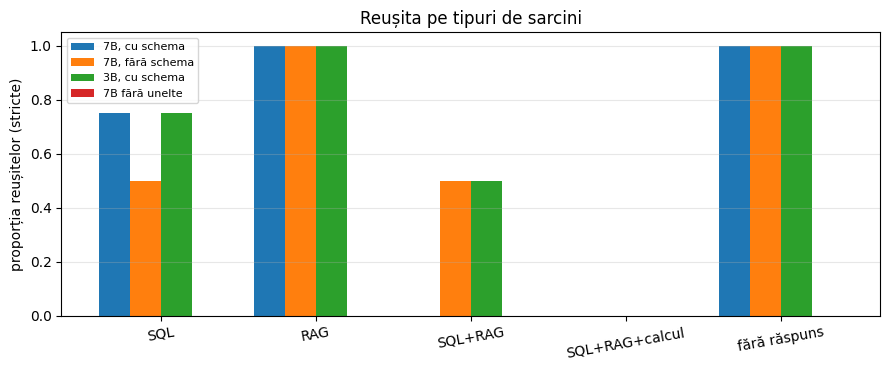

In [14]:
t0 = time.perf_counter()
EV_NS = evalueaza(cu_schema=False)
print(f"7.1 fără schemă — timp: {time.perf_counter() - t0:.0f} s")
EV_NS.drop(columns="trace").to_csv("artifacts/evaluare_agent_fara_schema.csv", index=False)

# 7.2: eliberez modelul 7B și încarc 3B
del llm; import gc; gc.collect()
if device == "cuda": torch.cuda.empty_cache()
tok, llm = load_llm(LLM_SMALL, four_bit=False)
t0 = time.perf_counter()
EV_3B = evalueaza(cu_schema=True)
print(f"7.2 model 3B — timp: {time.perf_counter() - t0:.0f} s")
EV_3B.drop(columns="trace").to_csv("artifacts/evaluare_agent_3B.csv", index=False)

REZ = pd.DataFrame([rezumat(EV, "7B, cu schema (principal)"), rezumat(EV_NS, "7B, fără schema"), rezumat(EV_3B, "3B, cu schema"),
                    {"variantă": "7B fără unelte", "răspunsuri corecte (din 13)": int(FARA["reușită"].sum())}])
display(REZ)
cmp = pd.DataFrame({"tip": EV["tip"], "7B cu schema": EV["reușită"], "7B fără schema": EV_NS["reușită"], "3B cu schema": EV_3B["reușită"],
                    "fără unelte (corect)": FARA["reușită"],
                    "pași 7B / 7B fără schema / 3B": EV["pași"].astype(str) + " / " + EV_NS["pași"].astype(str) + " / " + EV_3B["pași"].astype(str)})
cmp.index = EV["id"]; display(cmp)

fig, ax = plt.subplots(figsize=(9, 3.8))
tipuri = ["SQL", "RAG", "SQL+RAG", "SQL+RAG+calcul", "fără răspuns"]
x = np.arange(len(tipuri)); w = 0.2
for j, (nume, df) in enumerate([("7B, cu schema", EV), ("7B, fără schema", EV_NS), ("3B, cu schema", EV_3B), ("7B fără unelte", FARA)]):
    ax.bar(x + (j - 1.5) * w, [df[df.tip == t]["reușită"].mean() for t in tipuri], w, label=nume)
ax.set_xticks(x); ax.set_xticklabels(tipuri, rotation=10); ax.set_ylim(0, 1.05)
ax.set_ylabel("proporția reușitelor (stricte)"); ax.set_title("Reușita pe tipuri de sarcini"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

In [15]:
# urmele variantei 3B la sarcinile combinate, pentru comparația cu 7B
for _, row in EV_3B[EV_3B.tip.str.startswith("SQL+")].iterrows():
    print(f"■ {row['id']} — reușită: {row['reușită']} | unelte: {row['unelte folosite']} | răspuns: {row['răspuns'][:200]}")

■ C1 — reușită: True | unelte: ['cauta_regulament', 'interogare_sql'] | răspuns: Da, media lui Natalia Bălan este 8.5, care este suficientă pentru a participa la mobilitate academică. Pragul pentru profilul umanist este 8.5 [p. 8, pct. 57].
■ C2 — reușită: True | unelte: ['cauta_regulament', 'interogare_sql'] | răspuns: Da: Media lui este 6.75, care este sub pragul de 7.5 pentru profilul real. Nu poate participa la mobilitate academică în țară sau în străinătate.
■ C3 — reușită: False | unelte: ['__json_invalid__'] | răspuns: Nu am găsit informația. Pentru a calcula mediul general al Mihai Ceban, avem nevoie de media sa de la notele notele notele notele notele notele notele notele notele notele notele notele notele notele 
■ C4 — reușită: False | unelte: [] | răspuns: <tool_call>
{"name": "interogare_sql", "arguments": {"query": "SELECT credite FROM discipline WHERE denumire = 'Inteligența artificială generativă' LIMIT 1"}
}]
</tool_call>
■ C5 — reușită: False | unelte: ['interogare_sq

**Interpretare:**

| Variantă | Reușite stricte | Răspunsuri corecte | Unelte corecte | Pași (medie) | Erori unelte |
|---|---|---|---|---|---|
| 7B, cu schemă (principal) | 6 | 8 | 9 | 2,23 | 0 |
| 7B, fără schemă | 7 | 7 | 10 | 2,54 | 8 |
| 3B, cu schemă (prompt nou) | 8 | 8 | 8 | 1,77 | 2 |
| Prima versiune: 3B, prompt simplu | 3 reale (4 automat) | 4 | 6 | 1,77 | 1 |

**7.1 Schema în prompt.**
- Fără schemă, agentul și-a descoperit singur structura (`sqlite_master`), a făcut mai mulți pași (2,54 față de 2,23) și **8 erori SQL**, pe care și le-a corectat parțial. A obținut 7 reușite stricte, față de 6.
- Diferența de 1 sarcină nu e concludentă pe 13 sarcini. Pe tipuri, varianta fără schemă a „câștigat” C1 și C2, dar a pierdut S1.
- **Limită:** răspunsurile acestei variante nu sunt afișate în notebook (doar rezultatele automate), deci nu le-am putut verifica manual. Știu din 7.2 că verificarea automată a lăsat să treacă raționamente greșite la C1 și C2, deci cifra de 7 poate fi supraestimată.

**7.2 Mărimea modelului: 7B față de 3B.**
- **Automat, 3B a ieșit mai bine** (8 față de 6), dar urmele arată că 2 dintre cele 8 sunt **raționamente greșite** care au păcălit verificarea automată:
  - **C1 (3B):** „Pragul pentru profilul **umanist** este 8,5”. Natalia Bălan e la un program real (prag 7,5). Concluzia „Da” e corectă doar pentru că 8,5 ≥ 8,5.
  - **C2 (3B):** „**Da:** media lui este 6,75, care este sub pragul de 7,5 pentru profilul **real**. Nu poate participa…”. Profilul e greșit (Psihologia e umanist), iar răspunsul se contrazice singur.
- La verificarea manuală, **ambele modele au ~6 reușite reale**, toate la sarcinile simple.
- 3B a avut și un apel de unealtă stricat (C4: `}]` în plus), luat drept răspuns final, și o buclă de repetiție („notele notele notele…”) la C3.
- **Câștigul față de prima versiune** (de la 3 la ~6 reușite reale) vine deci din **prompt și unelte** (procedura, exemplul, indiciul de rezultat gol, repararea JSON), nu din modelul mai mare. Pe sarcinile combinate niciunul nu a rezolvat corect nimic, în nicio variantă cu schemă.

## 8. Concluzii, limitări și noțiuni

**Ce am construit:**
- un agent cu **3 unelte**: SQL pe o bază SQLite creată local, RAG pe regulamentul USM și un calculator sigur;
- o buclă *ReAct* scrisă de mână peste *tool calling*-ul nativ al Qwen2.5;
- o evaluare pe 13 sarcini, cu răspunsurile corecte calculate independent;
- **două iterații** de îmbunătățire, bazate pe urmele pașilor agentului.

**Ce a mers:**
- Mecanismul funcționează. Agentul alege unealta potrivită pentru întrebările simple, scrie SQL corect, citește regulamentul, își repară JSON-ul, reîncearcă după un rezultat gol și refuză când informația nu există.
- La întrebările care cer **o singură sursă** a răspuns corect la 5 din 6 cu 7B, plus refuzul de la N1.
- Fără unelte, modelul a avut **0 din 13** și a inventat reguli și cifre.

**Ce nu a mers:**
- Sarcinile **combinate** (bază + regulament + calcul): 0 din 6 reale, cu ambele modele.
- Agentul răspunde după prima sursă și „completează” regula din memorie, cu cifre și pagini inventate. Mai adaugă și filtre SQL inventate sau ia coloana greșită.
- Instrucțiunile din prompt („consultă ÎNTOTDEAUNA regulamentul”) nu au fost respectate consecvent de un model de 3–7B.

**Ce aș face mai departe:**
1. **Un verificator înainte de răspunsul final.** Dacă răspunsul conține un prag sau o regulă, dar `cauta_regulament` nu a fost apelat, ori citează o pagină pe care unealta n-a întors-o, agentul primește „verifică în regulament” și continuă. E un *guardrail* în cod, nu în prompt, deci nu depinde de ascultarea modelului.
2. **O unealtă specializată** `date_student(nume)`, care întoarce profilul, media notelor și creditele. Ar elimina erorile de SQL de la întrebările despre un singur student (C1–C3).
3. **Refuzul interogărilor identice** cu cea care tocmai a eșuat și un avertisment la folosirea `media_licenta` când se cere media notelor.
4. **Un model mai mare** (de exemplu 14B sau unul prin API). Diferența mică dintre 3B și 7B arată însă că, la această scară, structura agentului contează mai mult decât mărimea modelului.

**Limitări:**
- doar 13 sarcini, deci o sarcină înseamnă ~8 puncte procentuale;
- date fictive și o singură bază;
- verificarea automată e îngăduitoare la întrebările da/nu: 2 raționamente greșite ale modelului 3B au trecut. De aceea am verificat manual varianta principală și 3B, dar nu și varianta 7B fără schemă, ale cărei răspunsuri nu sunt afișate;
- o singură rulare: decodarea lacomă face rezultatele reproductibile pe același hardware, dar nu și pe alte versiuni de biblioteci.

**Noțiunile folosite, pe scurt:**
- **Agent:** un LLM care decide singur, în buclă, ce acțiune face (ce unealtă apelează și cu ce argumente), observă rezultatul și continuă până poate răspunde. Diferența față de RAG: la RAG căutarea se face mereu, o dată, înaintea generării. Aici modelul decide dacă, ce și de câte ori caută.
- ***Tool calling*:** modelul primește descrierea uneltelor în JSON Schema și răspunde cu un apel structurat (`<tool_call>{name, arguments}</tool_call>`). Codul rulează unealta, iar rezultatul revine ca mesaj `tool`.
- ***ReAct*:** alternanța raționament → acțiune → observație. Urma (*trace*) o face inspectabilă, iar din urme am găsit fiecare greșeală de mai sus.
- **Siguranța uneltelor:** conexiunea SQL e doar pentru citire, sunt acceptate doar `SELECT`-uri, iar calculatorul nu folosește `eval`. Un agent execută cod pe baza a ce generează un model, deci uneltele trebuie să limiteze ce poate face.
- **Cuantizarea pe 4 biți (NF4):** ponderile sunt stocate pe 4 biți în loc de 16, deci 7B ocupă ~5,5 GB în loc de ~15 GB și încape pe T4. Costul e o mică pierdere de precizie și o generare mai lentă (14,7 s pe sarcină față de 10,3 s la 3B).